# Role-based access reviews

Compare an application permission matrix with a least-privilege baseline.

Start from an explicit set of allowed role-action pairs. Unlisted combinations are denied. Comparing an observed configuration with this policy reveals excess grants and missing grants separately.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

reader export excess
auditor export missing


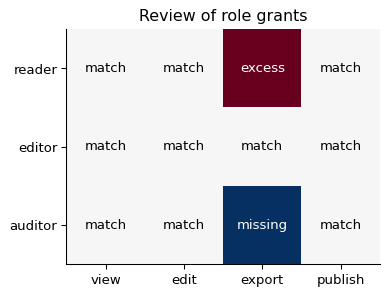

In [2]:
roles = ["reader", "editor", "auditor"]
actions = ["view", "edit", "export", "publish"]
expected = {"reader": {"view"}, "editor": {"view", "edit"}, "auditor": {"view", "export"}}
observed = {"reader": {"view", "export"}, "editor": {"view", "edit"}, "auditor": {"view"}}
baseline = np.array([[a in expected.get(r, set()) for a in actions] for r in roles])
actual = np.array([[a in observed.get(r, set()) for a in actions] for r in roles])
d = actual.astype(int) - baseline
for i, j in np.argwhere(d):
    print(roles[i], actions[j], "excess" if d[i, j] > 0 else "missing")
assert (
    (d == 1).sum() == 1
    and (d == -1).sum() == 1
    and "publish" not in expected.get("unknown", set())
)
fig, ax = plt.subplots(figsize=(5.7, 3), constrained_layout=True)
ax.imshow(d, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(
    xticks=range(4),
    xticklabels=actions,
    yticks=range(3),
    yticklabels=roles,
    title="Review of role grants",
)
for (i, j), v in np.ndenumerate(d):
    ax.text(
        j,
        i,
        {0: "match", 1: "excess", -1: "missing"}[v],
        ha="center",
        va="center",
        color="white" if v else "black",
    )
plt.show()

## Interpreting the result

An approval decision still depends on the resource and request context. Role summaries can hide object-level restrictions.

## Exercise

Add an intern role with one permitted action and construct a test for an unlisted action.

## References

[OWASP, Authorization Cheat Sheet](https://cheatsheetseries.owasp.org/cheatsheets/Authorization_Cheat_Sheet.html)